# C2 · Job–résumé matching and educational proxies

**Case:** Iso, Pezeshkpour, Bhutani & Hruschka (2025), NAACL Industry, *Evaluating Bias in LLMs for Job-Resume Matching: Gender, Race, and Education*.  
**Authoritative paper:** https://aclanthology.org/2025.naacl-industry.55/  
**Scope:** the original Machamp microdata are proprietary and the paper does not share the exact experiment records. This notebook uses a separately generated, transparent teaching simulation. It is not a reproduction of the original LLM results and does not substitute JobFair data under the Iso name.  
**Full guided lesson:** about 60–90 minutes.  
**Learning goal:** recognize a feature that changes decisions without improving job-relevant matching, and test a proposed correction without inventing empirical evidence.

### How students use this notebook

Run cells in order. Pause at every **Student task** and record your expectation before showing the worked answer. Name the numerator, denominator, unit and decision rule beside each reported number. The raw folder preserves inputs; the processed folder holds documented teaching tables. Rebuild processed data with `python scripts/process_data.py` from the package root. The source manifest records download versions and distinguishes generated inputs.

For the 150-minute lesson, your team completes the core sections assigned in `INSTRUCTOR_GUIDE.md`. The full notebook takes longer and can support self-study. Part 2 is deliberately unfinished. Running Part 1 supplies a baseline; it does not constitute a final project. Use only data whose provenance and permitted use you can explain.

**Instructor / course:** ____________________  
**Student / team / date:** ____________________

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "data/DATA_MANIFEST.json").exists())
sys.path.insert(0, str(ROOT / "src"))
from fairness_lab import (load_table, audit_table, confusion_counts, rates, rate_gaps,
    wilson_interval, bootstrap_mean_interval, paired_summary, matching_scores, alleged_age_veto)
SEED=42
pd.set_option("display.max_columns",25)
pd.set_option("display.max_rows",25)
pd.set_option("display.float_format",lambda x:f"{x:.4f}")
plt.rcParams.update({"figure.figsize":(9,4.5),"axes.spines.top":False,
    "axes.spines.right":False,"font.size":11})
%matplotlib inline
print("Local data only. No API key, paid model, or live LLM is needed.")

Local data only. No API key, paid model, or live LLM is needed.


## Part 1 — Theory, data engineering and a worked audit

### 1.1 What the paper studies

The original input is a job description paired with a résumé. The source Machamp dataset supplies matched/unmatched status. The experiment selected 400 base pairs across 40 occupational groups, with five matched and five unmatched pairs per group. It created 80 cue variations per base pair and evaluated 12 model snapshots: 32,000 variants and 384,000 model evaluations. A model evaluation is not an independent applicant.

The authors changed names and educational institution names and asked for a matching score from 1 to 10. Institution categories include Ivy League, HBCU, women's colleges and less-known colleges. Name or institution signals can correlate with demographic associations, prestige or unequal educational access. No institution category defines an individual's race or gender. A nonzero sensitivity can reflect a proxy problem, but identifying an unlawful or causal mechanism requires more evidence.

**Student task:** What remains fixed in a credible paired test? Which annotation assumptions make a matched/unmatched label job-relevant? What would you ask the data owner before treating a labelled match as ground truth?

### 1.2 Original design and our accessible data

| Item | Original paper | Included teaching simulation |
|---|---|---|
| Base records | 400 private job–résumé pairs | 18 invented qualification profiles across three jobs |
| Repeated observations | 80 cue variants per pair, 12 LLMs | Four institution categories × two arbitrary name cues = eight variants per pair |
| Inputs | Natural-language jobs/résumés and manipulated cues | Explicit skill tokens, experience, text templates and cue tags |
| Reference target | Source matching status | Invented rubric: all three required skills AND at least three years |
| Output | LLM score 1–10 | Disclosed arithmetic scorer 1–10, evaluated with and without planted proxy bonuses |
| Availability | Exact private experiment records absent | All 144 generated variants, generation code and processed tables included |

The simulation deliberately plants a mechanism that students can detect and remove. Its category effects are arbitrary. They do not estimate a school's quality, a demographic effect, or the behaviour of an actual LLM. Since it is a complete deterministic design, do not attach population p-values to repeated variants.

In [2]:
scope=json.loads((ROOT/"data/raw/02_iso_matching/SOURCE_AND_SCOPE.json").read_text())
display(pd.Series(scope["reported_design"],name="Original paper design"))
records=[json.loads(line) for line in
    (ROOT/"data/raw/02_iso_matching/synthetic_matching.jsonl").read_text().splitlines()]
raw=pd.DataFrame(records)
display(raw[["base_pair_id","job_id","required_skills","resume_skills","experience_years","institution_category"]].head())
print("144 variant rows;",raw.base_pair_id.nunique(),"base qualification profiles.")

occupational_groups     40
base_pairs             400
variants_per_pair       80
LLMs                    12
Name: Original paper design, dtype: int64

,base_pair_id,job_id,required_skills,resume_skills,experience_years,institution_category
0,data_analyst_1_1,data_analyst,"[python, sql, statistics]","[python, gardening]",1,Ivy League
1,data_analyst_1_1,data_analyst,"[python, sql, statistics]","[python, gardening]",1,Ivy League
2,data_analyst_1_1,data_analyst,"[python, sql, statistics]","[python, gardening]",1,HBCU
3,data_analyst_1_1,data_analyst,"[python, sql, statistics]","[python, gardening]",1,HBCU
4,data_analyst_1_1,data_analyst,"[python, sql, statistics]","[python, gardening]",1,Women’s college


144 variant rows; 18 base qualification profiles.


### 1.3 Features, target and processing decisions

| Field | Role | Handling |
|---|---|---|
| `variant_id`, `base_pair_id`, `job_id` | Traceability and repeated-unit keys | Preserve them through reshaping, splitting and peer review. |
| `required_skills`, `resume_skills`, `skill_hits` | Job-related teaching features | Exact token overlap is an artificial simplification. Real semantics and synonyms need rubric review. |
| `experience_years`, `required_years` | Job-related teaching features | The requirement of three years is an invented assumption, not a universally justified threshold. |
| `institution_category`, `name_cue` | Audit manipulations | Inspect their effect with relevant features fixed. Name A/B are arbitrary tags, not verified demographics. |
| `job_text`, `resume_text` | Synthetic text view | Entirely invented. No real applicant PII is needed. |
| `reference_match`, `y` | Constructed reference target | All skills plus sufficient experience. It has no external validation. |
| Computed `score_proxy`, `score_rubric` | Teaching output | Known formulas, not queried model responses or probabilities. |
| `decision` | Threshold rule | Match recommendation if score ≥8. Define the boundary explicitly. |

**Engineering task:** Parse JSONL, compute the set intersection, retain all variants, and serialize lists for the CSV loader. Do not split one base profile across training and test. The next cell reproduces the important feature/label transformations and checks the included table.

In [3]:
engineered=raw.copy()
engineered["skill_hits"]=[len(set(a)&set(b)) for a,b in
    zip(raw.required_skills,raw.resume_skills)]
engineered["y"]=((engineered.skill_hits==3)&(engineered.experience_years>=3)).astype(int)
data=load_table("02_iso_matching","matching_variants.csv")
assert data.variant_id.is_unique and data.base_pair_id.nunique()==18 and len(data)==144
assert np.array_equal(engineered.skill_hits,data.skill_hits)
assert np.array_equal(engineered.y,data.y)
assert data.groupby("base_pair_id").y.nunique().eq(1).all()
assert data.groupby("base_pair_id").size().eq(8).all()
display(data.groupby(["job_id","institution_category"]).size().rename("variant rows").unstack())

institution_category,HBCU,Ivy League,Other college,Women’s college
job_id,,,,
data_analyst,12,12,12,12
project_coordinator,12,12,12,12
software_engineer,12,12,12,12


### 1.4 A visible mechanism and a numerical prediction

The legitimate teaching score is `1 + 2×skill_hits + 2×min(experience_years/3,1)`, clipped to 1–10. The proxy version adds arbitrary institution bonuses (+0.8 for Ivy League, −0.4 for HBCU and women's-college tags, zero for the other tag) plus +0.2/−0.2 for Name A/B. These signs exist only to construct an inspectable problem.

**Student task:** For three skill hits and one year, the legitimate score is 7.667. Averaging the two name variants cancels the ±0.2 cue term. What is the Ivy-tag score? Does threshold 8 change the decision? Is the change an improvement under our reference rubric?

The answer is 8.467, which crosses the threshold even though the experience requirement is unmet. Inspect the implementation in `src/fairness_lab.py`; the scorer's mechanism is available to students. A deployed LLM would require a new experiment, not this formula.

In [4]:
data["score_rubric"]=matching_scores(data,use_proxy=False)
data["score_proxy"]=matching_scores(data,use_proxy=True)
THRESHOLD=8
data["decision"]=data.score_proxy.ge(THRESHOLD).astype(int)
data["decision_rubric"]=data.score_rubric.ge(THRESHOLD).astype(int)
example=data[(data.job_id=="data_analyst")&(data.skill_hits==3)&(data.experience_years==1)]
display(example[["institution_category","name_cue","y","score_rubric","score_proxy","decision"]])
assert np.isclose(example.query("institution_category=='Ivy League'").score_proxy.mean(),8.4666666667)
assert example.query("institution_category=='Ivy League'").decision.eq(1).all()

,institution_category,name_cue,y,score_rubric,score_proxy,decision
32,Ivy League,Name cue A,0,7.6667,8.6667,1
33,Ivy League,Name cue B,0,7.6667,8.2667,1
34,HBCU,Name cue A,0,7.6667,7.4667,0
35,HBCU,Name cue B,0,7.6667,7.0667,0
36,Women’s college,Name cue A,0,7.6667,7.4667,0
37,Women’s college,Name cue B,0,7.6667,7.0667,0
38,Other college,Name cue A,0,7.6667,7.8667,0
39,Other college,Name cue B,0,7.6667,7.4667,0


### 1.5 Visualize support and decisions before reporting bias

The support plot should establish that every cue condition has the same base-profile composition. Comparing raw group means with different job distributions would answer another question. The decision plot shows the mechanism's consequences at the declared threshold, rather than assuming that any score difference changes an opportunity.

**Student task:** Why do 144 plotted variants provide only 18 base profiles? If a paired difference appears in every job, is it evidence of a population effect, or evidence that the known planted rule behaves as designed?

,variants,base_profiles,mean_score,recommendation_rate
institution_category,,,,
HBCU,36,18,5.9333,0.1667
Ivy League,36,18,7.1333,0.4167
Other college,36,18,6.3333,0.1667
Women’s college,36,18,5.9333,0.1667


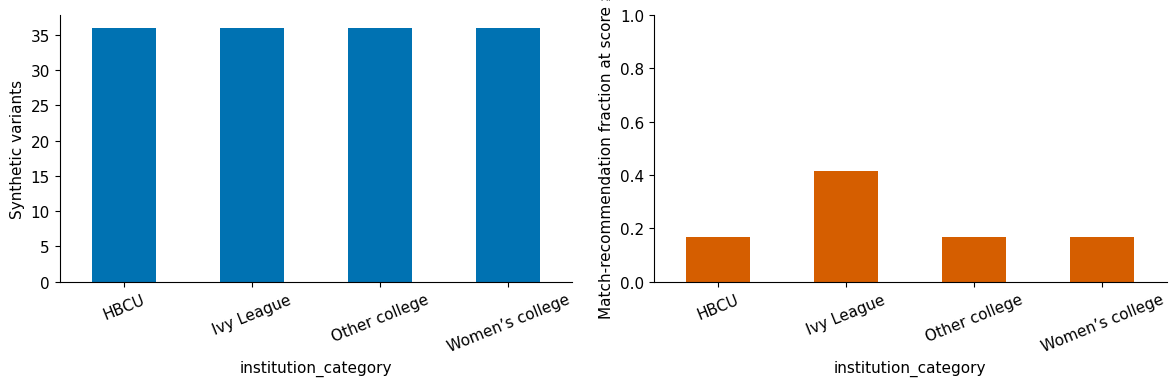

In [5]:
summary=data.groupby("institution_category").agg(variants=("variant_id","size"),
    base_profiles=("base_pair_id","nunique"),mean_score=("score_proxy","mean"),
    recommendation_rate=("decision","mean"))
display(summary)
fig,axes=plt.subplots(1,2,figsize=(12,4))
summary.variants.plot.bar(ax=axes[0],color="#0072B2");axes[0].set_ylabel("Synthetic variants")
summary.recommendation_rate.plot.bar(ax=axes[1],color="#D55E00")
axes[1].set_ylabel("Match-recommendation fraction at score ≥8");axes[1].set_ylim(0,1)
for ax in axes:ax.tick_params(axis="x",rotation=22)
plt.tight_layout();plt.show()

### 1.6 Paired proxy and direct-cue tests

Average the two name conditions within each base profile and institution category. Then compare institutions using the same profile. For the separate name test, hold institution fixed as well. The sign of the score difference follows the named reference. The flip rate divides differing decisions by complete paired conditions.

This is a controlled input-change test. Full counterfactual fairness would require a causal model describing how protected attributes influence qualification features. We do not infer a real candidate's race from a college or claim to identify those causal pathways.

**Student task:** Predict the name gap before running the calculation. Explain why clipping at 10 can make the observed gap smaller than the injected 0.4 points.

In [6]:
institution_pairs=data.groupby(["base_pair_id","institution_category"]).score_proxy.mean().unstack()
institution_gap=institution_pairs.subtract(institution_pairs["Other college"],axis=0)
display(institution_gap.mean().rename("Paired gap vs Other college (score points)"))
name_pairs=data.pivot(index=["base_pair_id","institution_category"],columns="name_cue",values="score_proxy")
name_pairs["gap_A_minus_B"]=name_pairs["Name cue A"]-name_pairs["Name cue B"]
name_pairs["flip_at_8"]=name_pairs["Name cue A"].ge(8).ne(name_pairs["Name cue B"].ge(8))
display(name_pairs.head(12))
print("Name score gap:",name_pairs.gap_A_minus_B.mean(),"points")
print("Name decision flips:",int(name_pairs.flip_at_8.sum()),"/",len(name_pairs))

institution_category
HBCU              -0.4000
Ivy League         0.8000
Other college      0.0000
Women’s college   -0.4000
Name: Paired gap vs Other college (score points), dtype: float64

name_cue                               Name cue A  Name cue B  gap_A_minus_B  \
base_pair_id     institution_category                                          
data_analyst_1_1 HBCU                      3.4667      3.0667         0.4000   
                 Ivy League                4.6667      4.2667         0.4000   
                 Other college             3.8667      3.4667         0.4000   
                 Women’s college           3.4667      3.0667         0.4000   
data_analyst_1_5 HBCU                      4.8000      4.4000         0.4000   
                 Ivy League                6.0000      5.6000         0.4000   
                 Other college             5.2000      4.8000         0.4000   
                 Women’s college           4.8000      4.4000         0.4000   
data_analyst_2_1 HBCU                      5.4667      5.0667         0.4000   
                 Ivy League                6.6667      6.2667         0.4000   
                 Other college             5.8667      5.4667         0.4000   
                 Women’s college           5.4667      5.0667         0.4000   

name_cue                               flip_at_8  
base_pair_id     institution_category             
data_analyst_1_1 HBCU                      False  
                 Ivy League                False  
                 Other college             False  
                 Women’s college           False  
data_analyst_1_5 HBCU                      False  
                 Ivy League                False  
                 Other college             False  
                 Women’s college           False  
data_analyst_2_1 HBCU                      False  
                 Ivy League                False  
                 Other college             False  
                 Women’s college           False

Name score gap: 0.39999999999999997 points
Name decision flips: 3 / 72


### 1.7 Error disparities require the reference target

Here `y=1` means the invented skill/experience rubric is satisfied and `decision=1` recommends a match. A false positive recommends a profile that fails that rubric. A false negative misses a profile that meets it. The target exists by design, so error rates can be calculated. This differs from C1, where actual job-performance labels are absent.

The denominators are all rubric nonmatches for FPR and all rubric matches for FNR. Undefined subgroups remain NaN. All reported results are conditional on the artificial rubric and profiles; a perfect result against a constructed label does not establish reliable real hiring.

**Planted proxy scorer: counts and error rates**

,n,positives,negatives,TP,FP,FN,TN,selection_rate,FPR,FNR
group,,,,,,,,,,
HBCU,36.0000,6.0000,30.0000,6.0000,0.0000,0.0000,30.0000,0.1667,0.0000,0.0000
Ivy League,36.0000,6.0000,30.0000,6.0000,9.0000,0.0000,21.0000,0.4167,0.3000,0.0000
Other college,36.0000,6.0000,30.0000,6.0000,0.0000,0.0000,30.0000,0.1667,0.0000,0.0000
Women’s college,36.0000,6.0000,30.0000,6.0000,0.0000,0.0000,30.0000,0.1667,0.0000,0.0000


**Rubric-only scorer on the identical profiles**

,n,TP,FP,FN,TN,selection_rate,FPR,FNR
group,,,,,,,,
HBCU,36.0000,6.0000,0.0000,0.0000,30.0000,0.1667,0.0000,0.0000
Ivy League,36.0000,6.0000,0.0000,0.0000,30.0000,0.1667,0.0000,0.0000
Other college,36.0000,6.0000,0.0000,0.0000,30.0000,0.1667,0.0000,0.0000
Women’s college,36.0000,6.0000,0.0000,0.0000,30.0000,0.1667,0.0000,0.0000


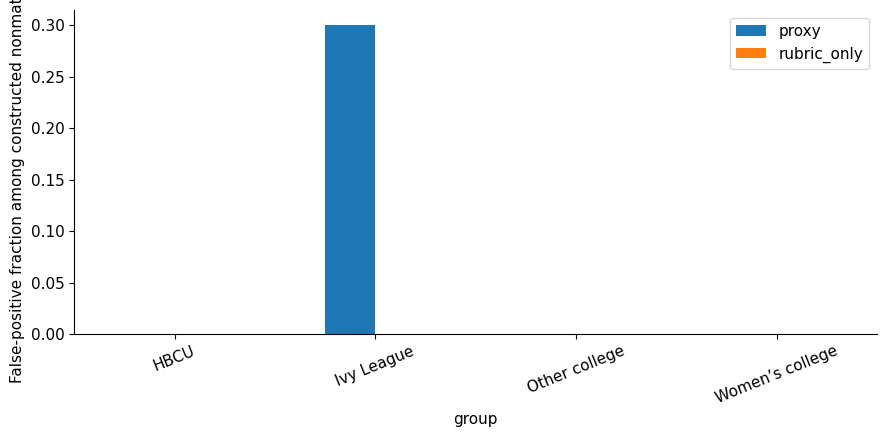

In [7]:
before=audit_table(data,group="institution_category")
after=audit_table(data.assign(decision=data.decision_rubric),group="institution_category")
display(Markdown("**Planted proxy scorer: counts and error rates**"))
display(before[["n","positives","negatives","TP","FP","FN","TN","selection_rate","FPR","FNR"]])
display(Markdown("**Rubric-only scorer on the identical profiles**"))
display(after[["n","TP","FP","FN","TN","selection_rate","FPR","FNR"]])
assert data.decision_rubric.eq(data.y).all()
comparison=pd.DataFrame({"proxy":before.FPR,"rubric_only":after.FPR})
comparison.plot.bar();plt.ylabel("False-positive fraction among constructed nonmatches")
plt.xticks(rotation=22);plt.tight_layout();plt.show()

### 1.8 Ethical diagnosis and practical responses

| Concern | How to recognize it | Proposed response | Remaining limitation |
|---|---|---|---|
| Educational proxy | Institution changes score with qualifications fixed | Justify education requirements by job tasks; test a structured rubric and masked-cue evaluation | Real education may have relevant and irrelevant pathways. Masking alone does not remove all proxies. |
| Direct cue sensitivity | Name-only pairs change scores or decisions | Audit multiple cues, request documented reasoning and review exclusions | Name A/B tags here have no actual demographic interpretation. |
| Questionable match labels | Annotators disagree or use prestige instead of job criteria | Use explicit job requirements and document disagreements, compensation and accessibility | Reference labels remain socially constructed and task-dependent. |
| Privacy and consent | Private résumé details enter logs or model requests | Use minimal, consented or fictional profiles and access controls | Public availability of some data would not automatically authorize new use. |
| Generalization | Complete synthetic grid is mistaken for market evidence | Obtain a separate permitted audit with realistic sampling and model/version logs | Simulation findings do not estimate real LLM bias. |

The implemented correction removes the known planted terms. It succeeds against this particular constructed reference because the simulation was designed that way. In a real system, prespecify the rubric and harms, validate on independent profiles, evaluate utility and accessibility, and monitor after changes. Human reviewers need authority and an appeal route; merely adding a reviewer does not guarantee a fair decision.

**Core-class output:** one controlled pair, the arithmetic 7.667 versus 8.467 calculation, a decision-flip table, and a proposed remedy with its validation requirement.

In [8]:
project_data=data.copy()
print("Part 1 baseline complete. Part 2 requires your own research question and extension.")

Part 1 baseline complete. Part 2 requires your own research question and extension.


## Part 2 — Final project, extension and self-study

### 2.1 A question you can test

**Starting question:** How do educational cues affect decisions when job-relevant evidence is fixed, and which proposed rubric remains robust to alternative assumptions?

**Independent unit:** one base job–résumé profile, keeping all its variants together. **Suggested primary quantity:** paired score difference or decision-flip rate with a named cue reference. Define the sign, reference group and practical effect threshold before comparing results. The primary criterion should follow a specific harm, rather than whichever number is easiest to equalize.

Possible extensions:
- Vary a skill/experience requirement and test who gains or loses.
- Compare masked cues with a job-task rubric.
- Design a new controlled multilingual or accessibility audit with permitted fictional profiles.

**TODO:** Write a protocol containing your decision, population, stakeholders, hypothesis, primary metric, independent unit, data permissions, split/resampling plan, intervention and evidence that could reverse your recommendation. Separate empirically checkable statements from ethical choices.

In [9]:
PROJECT_SPEC={
    "case_id":"C2","question":"TODO: one falsifiable question",
    "independent_unit":'one base job–résumé profile, keeping all its variants together',"primary_metric":'paired score difference or decision-flip rate with a named cue reference',
    "reference_group":"TODO","practical_effect_threshold":None,
    "validation_plan":"TODO","intervention":"TODO",
    "ethics_and_label_assumptions":"TODO","seed":SEED,
}
PROJECT_DIR=ROOT/"reports"/'C2'
PROJECT_DIR.mkdir(parents=True,exist_ok=True)
display(pd.Series(PROJECT_SPEC,name="Your research protocol"))

case_id                                                                        C2
question                                           TODO: one falsifiable question
independent_unit                one base job–résumé profile, keeping all its v...
primary_metric                  paired score difference or decision-flip rate ...
reference_group                                                              TODO
practical_effect_threshold                                                   None
validation_plan                                                              TODO
intervention                                                                 TODO
ethics_and_label_assumptions                                                 TODO
seed                                                                           42
Name: Your research protocol, dtype: object

### 2.2 TODO work packages and implementation hints

1. **TODO: Expand the generator.** Add two jobs and edge cases such as skill synonyms or career gaps. Hint: preserve base_pair_id and provide a documented reference rule for each job. Do not present invented profiles as sampled applicants.
2. **TODO: Compare one alternative solution.** Change the rubric, proxy handling or decision budget. Hint: decide the objective before seeing results and retain a separate set of generated profiles for evaluation.
3. **TODO: Test measurement sensitivity.** Reverse or remove planted bonuses and vary the skill definition. Hint: a detected category effect should track the implemented mechanism, while a causal claim needs additional assumptions.
4. **TODO: Plan or implement permitted annotation.** Create a blank multi-annotator rubric and record disagreement. Hint: compare agreement conditional on the job rather than declaring the most popular label true.
5. **TODO: Report the independent unit.** If resampling new stochastic profiles, resample base profiles, never variants. Hint: explain why bootstrapping this finite deterministic grid does not estimate labour-market uncertainty.
6. **TODO: If studying an actual model, design a separate prospective audit.** Document model version, prompts, order, repeats, valid-response rules and budget. Hint: start with fictional/consented content and keep model outputs separate from this scorer.

### 2.3 Validity, uncertainty and data stewardship

The exact Machamp records and original prompts/outputs are not reproduced. The simulation has three jobs and 18 base profiles. Educational tags do not reveal real identities. Do not turn the source paper’s regularized coefficients into a claim that all omitted categories are fair.

Keep related observations together. Fit transformations and models on training data, choose thresholds on validation data, and examine a final test set once. If you revise after seeing test results, obtain a fresh holdout or call the analysis exploratory. Report practical effect sizes and sample support with any interval. A deterministic teaching grid supports exhaustive rule checks and assumption sensitivity, not a population confidence interval.

Where you propose human annotation, specify the rubric, accessible instructions, disagreement resolution, annotator time, compensation and opt-out. Record disagreement rather than treating a majority vote as automatically unbiased truth. Avoid collecting real applicant résumés simply to enlarge a class project.

### 2.4 Further reading and independent study

Read Iso et al. sections 3 and the limitations. Contrast paired input edits with Kusner et al. (2017), https://arxiv.org/abs/1703.06856. Study scikit-learn GroupShuffleSplit for repeated-profile validation: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html

**Self-study challenge:** Identify one claim that these data cannot support. Design the smallest additional consented or fictional audit that could test it, including the sampling unit, target definition and privacy constraints.

In [10]:
def student_extension(data,spec):
    """TODO: return results_table, assumptions, uncertainty, limitations and recommendation."""
    raise NotImplementedError("Implement your extension; the guided baseline is only Part 1.")

RUN_STUDENT_PROJECT=False  # Enable only after implementing the extension.
if RUN_STUDENT_PROJECT:
    result=student_extension(project_data.copy(),PROJECT_SPEC)
    assert {"results_table","limitations","recommendation"}.issubset(result)
    display(result["results_table"])

### Final-project submission and assessment

Submit an extended notebook, an environment specification, a processing log, a data card, and a 1,500–2,500 word report. Include a reproducible baseline, one substantive extension, an uncertainty or assumption-sensitivity analysis, and a recommendation whose limits follow from the data. A project that simply reruns the worked cells needs further work.

Use the supplied protocol, data-card and audit-report templates. Keep immutable inputs unchanged and save your derived results in your case's `reports/` folder. List exclusions, missingness policies and failed runs. If you use AI assistance, identify it and verify its code and claims yourself. Explain one numerical calculation and one design choice in an oral defence without relying on an AI-generated answer.

| Assessment component | Weight | Evidence |
|---|---:|---|
| Question and justified fairness objective | 15% | Specific decision, affected people, independent unit and hypothesis |
| Data provenance, quality and ethical reasoning | 20% | Source, permitted use, missingness, label limitations and concrete actions |
| Reproducible implementation | 25% | Correct denominators, runnable pipeline and appropriate validation |
| Substantive extension and uncertainty | 25% | New analysis or intervention, effect size, assumptions and sensitivity |
| Interpretation and communication | 15% | Supported recommendation, tradeoffs and honest evidence boundaries |

**Peer review:** Another team should reproduce one figure and one number, identify its numerator and denominator, and challenge one assumption. Check an empty subgroup or zero denominator: an undefined error rate must remain undefined. Explain whose burden increases if your chosen criterion improves.

**Final check:** clean execution; sources cited; all TODOs addressed; no raw data silently modified; thresholds and positive-decision direction named; project extension demonstrated; conclusions distinguish descriptive, causal and legal claims; monitoring and appeal owner identified.